## بارگذاری کتابخانه‌های لازم

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## بارگذاری داده‌ها از فایل CSV

In [33]:
df = pd.read_csv('rawData.csv')
df.head()

,Age,BMI,Glucose,Insulin,DiastolicBP,Outcome
0,25,28.1,120,60,80,0
1,34,31.5,150,120,90,1
2,42,35.2,165,150,95,1
3,55,38.7,190,200,105,1
4,22,25.4,110,40,75,0


## بررسی اطلاعات اولیه داده‌ها

In [34]:
print("اطلاعات اولیه درباره داده‌ها:")
print(df.shape)
print(f"تعداد نمونه‌ها: {df.shape[0]}")
print(f"تعداد ویژگی‌ها: {df.shape[1]}")
print(f"نام ستون‌ها: {list(df.columns)}")

اطلاعات اولیه درباره داده‌ها:
(360, 6)
تعداد نمونه‌ها: 360
تعداد ویژگی‌ها: 6
نام ستون‌ها: ['Age', 'BMI', 'Glucose', 'Insulin', 'DiastolicBP', 'Outcome']


## بررسی نوع داده‌های هر ستون

In [35]:
print("نوع داده‌های هر ستون:")
print(df.dtypes)

نوع داده‌های هر ستون:
Age              int64
BMI            float64
Glucose          int64
Insulin          int64
DiastolicBP      int64
Outcome          int64
dtype: object


## بررسی مقادیر از دست رفته

In [36]:
print("مقادیر از دست رفته در هر ستون:")
print(df.isnull().sum())

مقادیر از دست رفته در هر ستون:
Age            0
BMI            0
Glucose        0
Insulin        0
DiastolicBP    0
Outcome        0
dtype: int64


## آمار توصیفی 

In [37]:
print("آمار توصیفی داده‌ها (میانگین، انحراف معیار، کمینه، بیشینه و ...):")
print(df.describe())

آمار توصیفی داده‌ها (میانگین، انحراف معیار، کمینه، بیشینه و ...):
              Age         BMI     Glucose     Insulin  DiastolicBP     Outcome
count  360.000000  360.000000  360.000000  360.000000   360.000000  360.000000
mean    43.063889   35.199167  173.302778  158.697222    99.580556    0.725000
std     14.961746    5.802038   38.454618   73.255572    14.690272    0.447136
min     20.000000   24.500000  102.000000   32.000000    68.000000    0.000000
25%     29.750000   30.175000  138.000000   89.500000    88.000000    0.000000
50%     41.000000   35.200000  173.000000  159.000000    99.000000    1.000000
75%     54.250000   39.700000  202.000000  212.000000   111.000000    1.000000
max     69.000000   45.800000  260.000000  310.000000   129.000000    1.000000


In [38]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

## مراحل پیش‌پردازش داده‌ها

### بررسی مقادیر گمشده

In [39]:
missing_values = df.isnull().sum()
print(missing_values)

Age            0
BMI            0
Glucose        0
Insulin        0
DiastolicBP    0
Outcome        0
dtype: int64


### seperate labels and features

In [40]:
y = df['Outcome']
X = df.drop('Outcome', axis = 1)
print(X)
print(y)

     Age   BMI  Glucose  Insulin  DiastolicBP
0     25  28.1      120       60           80
1     34  31.5      150      120           90
2     42  35.2      165      150           95
3     55  38.7      190      200          105
4     22  25.4      110       40           75
..   ...   ...      ...      ...          ...
355   63  43.0      235      255          123
356   27  29.7      138       82           88
357   38  34.4      174      156          100
358   54  39.9      210      212          113
359   68  45.4      250      295          128

[360 rows x 5 columns]
0      0
1      1
2      1
3      1
4      0
      ..
355    1
356    0
357    1
358    1
359    1
Name: Outcome, Length: 360, dtype: int64


## تقسیم داده به مجموعه آموزش و تست 

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"تعداد کل داده‌ها: {df.shape[0]}")
print(f"تعداد داده‌های آموزشی: {X_train.shape[0]} ({X_train.shape[0]/df.shape[0]*100:.1f}%)")
print(f"تعداد داده‌های تست: {X_test.shape[0]} ({X_test.shape[0]/df.shape[0]*100:.1f}%)")

تعداد کل داده‌ها: 360
تعداد داده‌های آموزشی: 288 (80.0%)
تعداد داده‌های تست: 72 (20.0%)


## استانداردسازی داده‌ها

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## decision Tree

In [43]:
from sklearn.tree import DecisionTreeClassifier
drugTree = DecisionTreeClassifier(criterion="gini", max_depth = 4)
drugTree

DecisionTreeClassifier(max_depth=4)

### train with decision tree model

In [44]:
drugTree.fit(X_train_scaled,y_train)

DecisionTreeClassifier(max_depth=4)

### make prediction

In [45]:
predTree = drugTree.predict(X_test_scaled)
print (predTree [0:5])
print (y_test [0:5])

[0 1 1 1 0]
224    0
42     1
285    1
302    1
56     0
Name: Outcome, dtype: int64


### calculate metrics

In [46]:
from sklearn import metrics
print("DecisionTrees's Accuracy: ", metrics.accuracy_score(y_test, predTree))
print("DecisionTrees's precision: ", metrics.precision_score(y_test, predTree, average='macro'))
print("DecisionTrees's recall: ", metrics.recall_score(y_test, predTree, average='macro'))
print("DecisionTrees's f1_score: ", metrics.f1_score(y_test, predTree, average='macro'))

DecisionTrees's Accuracy:  0.9861111111111112
DecisionTrees's precision:  0.975
DecisionTrees's recall:  0.9905660377358491
DecisionTrees's f1_score:  0.9824175824175825



Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.98      0.99        53

    accuracy                           0.99        72
   macro avg       0.97      0.99      0.98        72
weighted avg       0.99      0.99      0.99        72



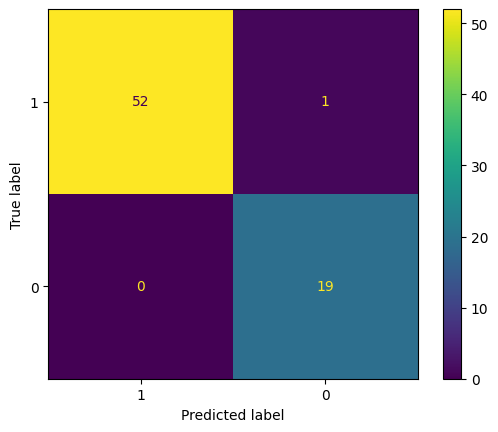

In [47]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Compute confusion matrix
cnf = confusion_matrix(y_test, predTree)

# y_test are your true labels and yhat are your predicted labels
ConfusionMatrixDisplay.from_predictions(y_test, predTree, labels=[1,0])

report = classification_report(y_test,predTree)
print("\nClassification Report:")
print(report)

## explanation: positive(1) means patient has diabets and negative(0) means patient doesn't have diabets
### count of TP = 52, count of FP = 0, count of TN = 19, count of FN = 1

## KNN model

In [48]:
from sklearn.neighbors import KNeighborsClassifier

### train

In [49]:
k = 4
#Train Model and Predict  
neigh = KNeighborsClassifier(n_neighbors = k).fit(X_train_scaled,y_train)
neigh

KNeighborsClassifier(n_neighbors=4)

### predict

In [50]:
yhat = neigh.predict(X_test_scaled)

print (yhat[0:5])
print (y_test[0:5])

[0 1 1 1 0]
224    0
42     1
285    1
302    1
56     0
Name: Outcome, dtype: int64


In [51]:
print("Test set Accuracy: ", metrics.accuracy_score(y_test, yhat))
print("Test set Precision: ", metrics.precision_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.recall_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.f1_score(y_test, yhat, average='macro'))

Test set Accuracy:  0.9861111111111112
Test set Precision:  0.975
Test set Precision:  0.9905660377358491
Test set Precision:  0.9824175824175825



Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.98      0.99        53

    accuracy                           0.99        72
   macro avg       0.97      0.99      0.98        72
weighted avg       0.99      0.99      0.99        72



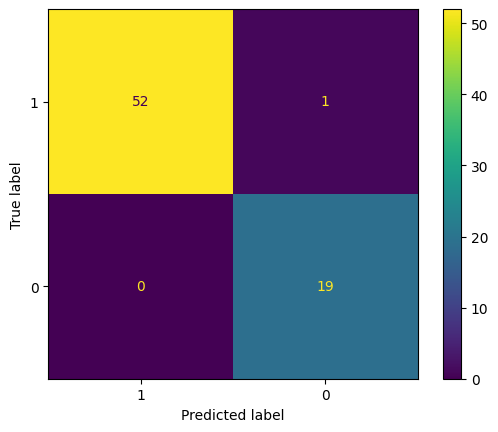

In [52]:
# Compute confusion matrix
cnf = confusion_matrix(y_test, predTree)

# y_test are your true labels and yhat are your predicted labels
ConfusionMatrixDisplay.from_predictions(y_test, predTree, labels=[1,0])

report = classification_report(y_test,predTree)
print("\nClassification Report:")
print(report)

## explanation: positive(1) means patient has diabets and negative(0) means patient doesn't have diabets
### count of TP = 52, count of FP = 0, count of TN = 19, count of FN = 1

In [53]:
from sklearn import svm
clf = svm.SVC(kernel='rbf')
clf.fit(X_train_scaled, y_train)

SVC()

In [54]:
yhat = clf.predict(X_test_scaled)
yhat [0:5]

array([0, 1, 1, 1, 0], dtype=int64)

In [55]:
print("Test set Accuracy: ", metrics.accuracy_score(y_test, yhat))
print("Test set Precision: ", metrics.precision_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.recall_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.f1_score(y_test, yhat, average='macro'))

Test set Accuracy:  0.9861111111111112
Test set Precision:  0.975
Test set Precision:  0.9905660377358491
Test set Precision:  0.9824175824175825



Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.98      0.99        53

    accuracy                           0.99        72
   macro avg       0.97      0.99      0.98        72
weighted avg       0.99      0.99      0.99        72



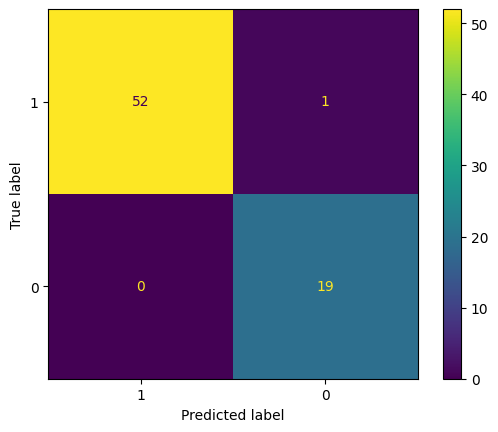

In [56]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay


# Compute confusion matrix
cnf = confusion_matrix(y_test, yhat)

# y_test are your true labels and yhat are your predicted labels
ConfusionMatrixDisplay.from_predictions(y_test, yhat, labels=[1,0])

report = classification_report(y_test, yhat)
print("\nClassification Report:")
print(report)

## explanation: positive(1) means patient has diabets and negative(0) means patient doesn't have diabets
### count of TP = 52, count of FP = 0, count of TN = 19, count of FN = 1

### Naive Bayes Model

In [57]:
from sklearn.naive_bayes import GaussianNB

In [58]:
NBmodel = GaussianNB()
NBmodel.fit(X_train_scaled, y_train)
yhat = NBmodel.predict(X_test_scaled)
yhat

array([0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1], dtype=int64)

In [59]:
print("Test set Accuracy: ", metrics.accuracy_score(y_test, yhat))
print("Test set Precision: ", metrics.precision_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.recall_score(y_test, yhat, average='macro'))
print("Test set Precision: ", metrics.f1_score(y_test, yhat, average='macro'))

Test set Accuracy:  0.9861111111111112
Test set Precision:  0.975
Test set Precision:  0.9905660377358491
Test set Precision:  0.9824175824175825



Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.98      0.99        53

    accuracy                           0.99        72
   macro avg       0.97      0.99      0.98        72
weighted avg       0.99      0.99      0.99        72



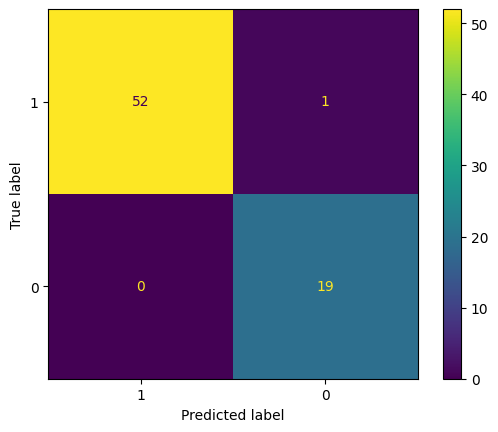

In [60]:
# Compute confusion matrix
cnf1 = confusion_matrix(y_test, yhat)

# y_test are your true labels and yhat are your predicted labels
ConfusionMatrixDisplay.from_predictions(y_test, yhat, labels=[1,0])

report = classification_report(y_test, yhat)
print("\nClassification Report:")
print(report)

## explanation: positive(1) means patient has diabets and negative(0) means patient doesn't have diabets
### count of TP = 52, count of FP = 0, count of TN = 19, count of FN = 1

<div dir="rtl" style="font-family: Tahoma; line-height: 1.9;">

<h3>ارزیابی و تفسیر نتایج مدل‌ها</h3>

<p>
بر اساس نتایج به‌دست‌آمده، تمامی مدل‌های به‌کاررفته در این پروژه ماتریس درهم‌ریختگی یکسانی روی داده‌های آزمون تولید کرده‌اند.
مقادیر ماتریس درهم‌ریختگی به صورت زیر است:
</p>

<ul>
  <li>True Positive (TP) = 52</li>
  <li>True Negative (TN) = 19</li>
  <li>False Positive (FP) = 0</li>
  <li>False Negative (FN) = 1</li>
</ul>

<p>
تعداد کل نمونه‌های مجموعه آزمون برابر با 72 نمونه است.
</p>

<p>
بر اساس این مقادیر، معیارهای ارزیابی مهم محاسبه شدند:
</p>

<div dir="ltr" style="margin-left:20px;">
Accuracy = (TP + TN) / Total = (52 + 19) / 72 ≈ 0.986 <br>
Recall = TP / (TP + FN) = 52 / (52 + 1) ≈ 0.981 <br>
Specificity = TN / (TN + FP) = 19 / (19 + 0) = 1 <br>
Precision = TP / (TP + FP) = 52 / (52 + 0) = 1 <br>
F1-score ≈ 0.99
</div>

<p>
تحلیل ماتریس درهم‌ریختگی نشان می‌دهد که مدل‌ها تنها در یک مورد بیمار دیابتی را
به اشتباه به‌عنوان فرد سالم تشخیص داده‌اند (False Negative = 1).
در مسائل پزشکی، به‌ویژه در غربالگری بیماری دیابت، خطای منفی کاذب از اهمیت بسیار بالایی برخوردار است،
زیرا عدم تشخیص به‌موقع بیمار می‌تواند منجر به تأخیر در درمان و بروز عوارض جدی شود.
بنابراین پایین بودن مقدار False Negative یکی از نقاط قوت مهم مدل‌های به‌کاررفته در این پروژه محسوب می‌شود.
</p>

<p>
از سوی دیگر، مقدار False Positive برابر صفر است که نشان می‌دهد هیچ فرد سالمی
به اشتباه بیمار تشخیص داده نشده است.
این موضوع باعث افزایش اعتماد به نتایج مدل و جلوگیری از ایجاد نگرانی یا درمان غیرضروری برای افراد سالم می‌شود.
</p>

<p>
در مجموع، با توجه به برابری نتایج عددی و ماتریس‌های درهم‌ریختگی در تمامی مدل‌ها،
نمی‌توان یک مدل را صرفاً از نظر عملکرد عددی برتر از سایرین دانست.
با این حال، تمامی مدل‌ها عملکرد بسیار مطلوبی در تشخیص بیماری دیابت نشان داده‌اند
و می‌توانند به‌عنوان ابزار پشتیبان تصمیم‌گیری در غربالگری اولیه دیابت مورد استفاده قرار گیرند.
انتخاب نهایی مدل مناسب می‌تواند بر اساس معیارهای کیفی مانند تفسیرپذیری،
پیچیدگی مدل و سهولت پیاده‌سازی انجام شود.
</p>

</div>